# Submission 2 — Pretrained Models, With and Without Fine-Tuning

**Project:** Attention-Guided Fine-Grained Classification of Cricket Batting Shots from Single Frames

---

### What this notebook does

Six training runs: **three ImageNet backbones × two transfer-learning modes.**

| Backbone | Frozen | Fine-tuned |
|---|---|---|
| ResNet50 | ✓ | ✓ |
| EfficientNetB0 | ✓ | ✓ |
| DenseNet121 | ✓ | ✓ |

**Frozen** — the backbone is a fixed feature extractor; only the classification head trains.
**Fine-tuned** — the backbone weights also update, at a reduced learning rate.

For every run: accuracy curve, loss curve, per-class classification report, test-set
confusion matrix, training time and inference time.

### Carried over from Submission 1

These are not re-decided here. They are inherited so that every comparison, through to
Submission 4, is attributable.

| Setting | Value | Why |
|---|---|---|
| Split | 70/15/15, grouped by duplicate identity | 608 redundant copies (12.9%) would otherwise leak across partitions |
| Seed | 42 | reproducibility |
| Channel conversion | force RGB | 4,586 of 4,724 images are RGBA |
| Resize | 224 × 224 | 84 distinct native sizes |
| Horizontal flip | **not applied** | mirroring converts a leg-side shot into an off-side one |
| Class weights | not applied | imbalance is 1.12 : 1 |

> **Before you push:** Run → Restart & Run All, so every plot and table is saved in the `.ipynb`.

> **Runtime:** roughly 1.5–2.5 hours on a Kaggle GPU. Set `SMOKE_TEST = True` in the
> config cell to do a 2-epoch dry run first and confirm nothing breaks.

## Setup

In [1]:
import os, sys, time, json, warnings, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore")

# ---- reproducibility ----
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})

gpus = tf.config.list_physical_devices("GPU")
print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("GPU        :", [g.name for g in gpus] if gpus else "NONE - this will be very slow")
if not gpus:
    print("\n  !! Settings -> Accelerator -> GPU, then re-run.")

tensorflow : 2.21.0
keras      : 3.13.2
GPU        : ['/physical_device:GPU:0', '/physical_device:GPU:1']


## Configuration

Everything tunable lives here. Nothing below this cell should need editing.

In [2]:
# ---- experiment configuration -------------------------------------------
SMOKE_TEST   = False     # True -> 2 epochs per run, to verify the pipeline works

IMG_SIZE     = 224
BATCH_SIZE   = 32
EPOCHS       = 40        # rubric asks for 30-50
PATIENCE     = 8         # early-stopping patience on val_loss

LR_FROZEN    = 1e-3      # head only, backbone fixed
LR_FINETUNE  = 1e-4      # backbone also updating -> smaller steps

DROPOUT      = 0.3
N_CLASSES    = 4

if SMOKE_TEST:
    EPOCHS, PATIENCE = 2, 2
    print(">>> SMOKE TEST: 2 epochs per run. Set SMOKE_TEST=False for the real thing.\n")

# Expected split sizes, from Submission 1. Used as a consistency check.
EXPECTED_SPLIT = {"train": 3321, "val": 682, "test": 721}
EXPECTED_TOTAL = 4724

print(f"epochs={EPOCHS}  batch={BATCH_SIZE}  img={IMG_SIZE}  "
      f"lr_frozen={LR_FROZEN}  lr_finetune={LR_FINETUNE}")

epochs=40  batch=32  img=224  lr_frozen=0.001  lr_finetune=0.0001


## Part 1 — Reconstruct the frozen split

Submission 1 wrote `split_manifest.csv` to its own Kaggle session, which does not carry
over to this notebook. Rather than depend on a file transfer, the split is **recomputed
from the same deterministic procedure** — identical file ordering, identical perceptual
hashes, identical seed — and then **verified against the counts Submission 1 produced.**

If the assertion at the end of Part 1 passes, this split is provably the same one.

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content"]
MIN_CLASSES, MIN_IMAGES_PER_CLASS = 2, 5


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            if cur.count(os.sep) - base >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            counts = {d: _count_images(os.path.join(cur, d)) for d in sorted(dirs)}
            good = [d for d, n in counts.items() if n >= MIN_IMAGES_PER_CLASS]
            if len(good) >= MIN_CLASSES:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


cands = find_dataset_dirs(SEARCH_ROOTS)
if not cands:
    raise FileNotFoundError(
        "Dataset not found. Add 'Cricket Shots Dataset' via + Add Input.")
cands.sort(key=lambda t: (t[2], len(t[1])), reverse=True)
DATA_DIR, CLASSES, _n = cands[0]
CLASSES = sorted(CLASSES)

print("DATA_DIR :", DATA_DIR)
print("classes  :", CLASSES)
print("images   :", f"{_n:,}")

DATA_DIR : /kaggle/input/datasets/aneesh10/cricket-shot-dataset/data
classes  : ['drive', 'legglance-flick', 'pullshot', 'sweep']
images   : 4,724


In [4]:
def dhash(path, hash_size=8):
    """64-bit perceptual difference hash. Identical to Submission 1."""
    with Image.open(path) as im:
        im = im.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
        a = np.asarray(im, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


rows = []
for cls in CLASSES:
    cdir = os.path.join(DATA_DIR, cls)
    for fname in sorted(os.listdir(cdir)):
        if os.path.splitext(fname)[1].lower() in IMG_EXTS:
            rows.append({"path": os.path.join(cdir, fname),
                         "file": fname, "label": cls})
df = pd.DataFrame(rows)

print(f"indexing {len(df):,} files, hashing ...")
df["dhash"] = [dhash(p) for p in df["path"]]

hash_groups = df.groupby("dhash").indices
group_of = {}
for gid, (h, idx) in enumerate(hash_groups.items()):
    for i in idx:
        group_of[i] = gid
df["group_id"] = pd.Series(group_of).reindex(df.index).values

print(f"unique groups : {df.group_id.nunique():,} of {len(df):,} files")
print(f"redundant     : {len(df) - df.group_id.nunique():,} "
      f"({(len(df)-df.group_id.nunique())/len(df)*100:.1f}%)")

indexing 4,724 files, hashing ...
unique groups : 4,116 of 4,724 files
redundant     : 608 (12.9%)


In [5]:
# ---- grouped, stratified 70/15/15 split (identical to Submission 1) -----
grp = (df.groupby("group_id")
         .agg(label=("label", "first"))
         .reset_index())

train_g, temp_g = train_test_split(
    grp, test_size=0.30, stratify=grp["label"], random_state=RANDOM_SEED)
val_g, test_g = train_test_split(
    temp_g, test_size=0.50, stratify=temp_g["label"], random_state=RANDOM_SEED)

split_of = {}
for name, part in [("train", train_g), ("val", val_g), ("test", test_g)]:
    for g in part["group_id"]:
        split_of[g] = name
df["split"] = df["group_id"].map(split_of)

pivot = df.pivot_table(index="label", columns="split", values="path",
                       aggfunc="count").reindex(CLASSES)[["train", "val", "test"]]
pivot["total"] = pivot.sum(axis=1)
print(pivot.to_string())

actual = dict(df.split.value_counts())
print("\nsplit sizes :", {k: int(actual[k]) for k in ["train", "val", "test"]})

# ---- consistency checks -------------------------------------------------
assert df.groupby("group_id").split.nunique().max() == 1, \
    "LEAKAGE: a duplicate group spans more than one split"

mismatch = [k for k, v in EXPECTED_SPLIT.items() if int(actual.get(k, -1)) != v]
if len(df) != EXPECTED_TOTAL or mismatch:
    print("\n  !! WARNING: split does not match Submission 1.")
    print(f"     expected {EXPECTED_SPLIT} total {EXPECTED_TOTAL}")
    print(f"     got      {dict(actual)} total {len(df)}")
    print("     Results will still be valid internally, but Submission 1's")
    print("     reported numbers refer to a different partition.")
else:
    print("\nSplit reproduces Submission 1 exactly. Leakage check passed.")

df[["path", "file", "label", "group_id", "split"]].to_csv(
    "split_manifest.csv", index=False)

split            train  val  test  total
label                                   
drive              862  180   182   1224
legglance-flick    781  160   179   1120
pullshot           888  186   186   1260
sweep              790  156   174   1120

split sizes : {'train': 3321, 'val': 682, 'test': 721}

Split reproduces Submission 1 exactly. Leakage check passed.


## Part 2 — Load images into memory

4,724 images at 224×224×3 as `uint8` is about 710 MB, which fits comfortably in Kaggle's
RAM. Loading once into arrays is both simpler and faster than a file-reading `tf.data`
pipeline, and it sidesteps a real problem: the dataset mixes PNG, JPEG and WebP, and
TensorFlow's native decoders do not handle WebP. Pillow handles all three uniformly, and
`.convert("RGB")` resolves the RGBA issue in the same pass.

The arrays are cached to `.npy`, so a re-run of this notebook skips the decode entirely.

In [6]:
# /tmp, not /kaggle/working: a ~700 MB cache would bloat the notebook output
CACHE = "/tmp/images_224.npz"


def load_split(frame):
    X = np.zeros((len(frame), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.zeros(len(frame), dtype=np.int32)
    cls_to_idx = {c: i for i, c in enumerate(CLASSES)}
    for i, (_, r) in enumerate(frame.iterrows()):
        with Image.open(r["path"]) as im:
            im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            X[i] = np.asarray(im, dtype=np.uint8)
        y[i] = cls_to_idx[r["label"]]
    return X, y


if os.path.exists(CACHE):
    print("loading cached arrays ...")
    z = np.load(CACHE)
    Xtr, ytr = z["Xtr"], z["ytr"]
    Xva, yva = z["Xva"], z["yva"]
    Xte, yte = z["Xte"], z["yte"]
else:
    t0 = time.time()
    print("decoding images (one-off, ~1-2 min) ...")
    Xtr, ytr = load_split(df[df.split == "train"])
    Xva, yva = load_split(df[df.split == "val"])
    Xte, yte = load_split(df[df.split == "test"])
    np.savez(CACHE, Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)
    print(f"done in {time.time()-t0:.0f}s, cached to {CACHE}")

for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(f"{name:>6}: X{X.shape} {X.dtype}   y{y.shape}   "
          f"class counts {np.bincount(y, minlength=N_CLASSES).tolist()}")

print(f"\nmemory: {(Xtr.nbytes + Xva.nbytes + Xte.nbytes)/1e9:.2f} GB")
print("class index order:", {i: c for i, c in enumerate(CLASSES)})

decoding images (one-off, ~1-2 min) ...
done in 34s, cached to /tmp/images_224.npz
 train: X(3321, 224, 224, 3) uint8   y(3321,)   class counts [862, 781, 888, 790]
   val: X(682, 224, 224, 3) uint8   y(682,)   class counts [180, 160, 186, 156]
  test: X(721, 224, 224, 3) uint8   y(721,)   class counts [182, 179, 186, 174]

memory: 0.71 GB
class index order: {0: 'drive', 1: 'legglance-flick', 2: 'pullshot', 3: 'sweep'}


## Part 3 — Model construction

### Augmentation

Applied as layers inside the model, so they run on GPU and are automatically active
during training and inactive during evaluation. **No horizontal flip** — Submission 1
established that mirroring changes the correct label for leg-side strokes.

### Why `preprocess_input` lives inside the model

Each backbone expects a different input scaling: ResNet50 uses Caffe-style mean
subtraction, DenseNet uses Torch-style normalisation, EfficientNet expects raw `[0, 255]`.
Putting the model-specific preprocessing inside each model lets all six runs share one
set of `uint8` arrays, with no chance of applying the wrong normalisation.

### BatchNorm handling

The backbone is always called with `training=False`, which keeps its BatchNorm layers in
inference mode. This is the standard Keras transfer-learning pattern: updating BatchNorm
statistics on a small dataset while fine-tuning destabilises training and is a common
cause of fine-tuned models performing *worse* than frozen ones.

In [7]:
def make_augmentation():
    """Built fresh per model: clear_session() between runs invalidates any
    layer objects created before it."""
    return keras.Sequential([
        layers.RandomRotation(10 / 360, fill_mode="reflect"),   # +/- 10 degrees
        layers.RandomZoom(0.2, fill_mode="reflect"),            # scale 0.8-1.0
        layers.RandomBrightness(0.2, value_range=(0, 255)),
        layers.RandomContrast(0.2),
        # NO RandomFlip - see Submission 1, Finding 3
    ], name="augmentation")


BACKBONES = {
    "ResNet50": (keras.applications.ResNet50,
                 keras.applications.resnet50.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0,
                       keras.applications.efficientnet.preprocess_input),
    "DenseNet121": (keras.applications.DenseNet121,
                    keras.applications.densenet.preprocess_input),
}


def build_model(name, finetune):
    """Backbone + head. finetune=False freezes the backbone entirely."""
    ctor, preprocess = BACKBONES[name]
    base = ctor(weights="imagenet", include_top=False, pooling="avg",
                input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = finetune
    if finetune:
        # keep BatchNorm in inference mode even when fine-tuning
        for layer in base.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = make_augmentation()(inputs)
    x = preprocess(x)
    x = base(x, training=False)
    x = layers.Dropout(DROPOUT, name="dropout")(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=f"{name}_{'finetuned' if finetune else 'frozen'}")
    model.compile(
        optimizer=keras.optimizers.Adam(LR_FINETUNE if finetune else LR_FROZEN),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


# sanity check on parameter counts
_m = build_model("ResNet50", finetune=False)
print(f"ResNet50 frozen    : {_m.count_params():,} total, "
      f"{sum(np.prod(w.shape) for w in _m.trainable_weights):,} trainable")
del _m
_m = build_model("ResNet50", finetune=True)
print(f"ResNet50 fine-tuned: {_m.count_params():,} total, "
      f"{sum(np.prod(w.shape) for w in _m.trainable_weights):,} trainable")
del _m
keras.backend.clear_session()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet50 frozen    : 23,595,908 total, 8,196 trainable
ResNet50 fine-tuned: 23,595,908 total, 23,489,668 trainable


## Part 4 — Train and evaluate

One function handles a single configuration: train with early stopping, time it,
evaluate on the held-out test set, and return every metric the rubric asks for.

In [8]:
def run_experiment(name, finetune):
    tag = f"{name} ({'fine-tuned' if finetune else 'frozen'})"
    print("\n" + "=" * 68)
    print(f"  {tag}")
    print("=" * 68)

    keras.backend.clear_session()
    tf.random.set_seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)

    model = build_model(name, finetune)

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=max(3, PATIENCE // 2),
                                          min_lr=1e-7, verbose=1),
    ]

    t0 = time.time()
    hist = model.fit(Xtr, ytr,
                     validation_data=(Xva, yva),
                     epochs=EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=callbacks, verbose=2)
    train_time = time.time() - t0

    t0 = time.time()
    probs = model.predict(Xte, batch_size=BATCH_SIZE, verbose=0)
    test_time = time.time() - t0
    pred = probs.argmax(axis=1)

    acc = accuracy_score(yte, pred)
    p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(
        yte, pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(
        yte, pred, average="weighted", zero_division=0)
    p_c, r_c, f_c, sup = precision_recall_fscore_support(
        yte, pred, average=None, labels=range(N_CLASSES), zero_division=0)

    epochs_ran = len(hist.history["loss"])
    best_val = min(hist.history["val_loss"])
    gap = hist.history["accuracy"][-1] - hist.history["val_accuracy"][-1]

    print(f"\n  test accuracy : {acc:.4f}")
    print(f"  macro F1      : {f_mac:.4f}")
    print(f"  epochs ran    : {epochs_ran} / {EPOCHS}")
    print(f"  train time    : {train_time/60:.1f} min   "
          f"({train_time/epochs_ran:.1f}s per epoch)")
    print(f"  test time     : {test_time:.2f}s "
          f"({test_time/len(Xte)*1000:.2f} ms per image)")
    print(f"  train-val acc gap at stop: {gap:+.4f}")

    print("\n" + classification_report(yte, pred, target_names=CLASSES,
                                        digits=4, zero_division=0))

    return {
        "model": name, "mode": "fine-tuned" if finetune else "frozen", "tag": tag,
        "accuracy": acc, "precision_macro": p_mac, "recall_macro": r_mac,
        "f1_macro": f_mac, "precision_weighted": p_w, "recall_weighted": r_w,
        "f1_weighted": f_w,
        "per_class_precision": p_c.tolist(), "per_class_recall": r_c.tolist(),
        "per_class_f1": f_c.tolist(), "support": sup.tolist(),
        "train_time_s": train_time, "test_time_s": test_time,
        "ms_per_image": test_time / len(Xte) * 1000,
        "epochs_ran": epochs_ran, "best_val_loss": best_val,
        "overfit_gap": gap,
        "total_params": int(model.count_params()),
        "trainable_params": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        "history": {k: [float(v) for v in vs] for k, vs in hist.history.items()},
        "confusion": confusion_matrix(yte, pred, labels=range(N_CLASSES)).tolist(),
        "y_pred": pred.tolist(),
    }

In [9]:
CONFIGS = [(n, ft) for n in BACKBONES for ft in (False, True)]
print("planned runs:")
for i, (n, ft) in enumerate(CONFIGS, 1):
    print(f"  {i}. {n} ({'fine-tuned' if ft else 'frozen'})")

results = []
wall0 = time.time()

for name, ft in CONFIGS:
    try:
        results.append(run_experiment(name, ft))
        with open("results.json", "w") as f:
            json.dump(results, f, indent=1)
    except Exception as e:
        print(f"\n  !! {name} ({'fine-tuned' if ft else 'frozen'}) FAILED: {e!r}")
        print("     continuing with the remaining runs.")

print("\n" + "=" * 68)
print(f"  {len(results)} / {len(CONFIGS)} runs completed "
      f"in {(time.time()-wall0)/60:.1f} min total")
print("=" * 68)

planned runs:
  1. ResNet50 (frozen)
  2. ResNet50 (fine-tuned)
  3. EfficientNetB0 (frozen)
  4. EfficientNetB0 (fine-tuned)
  5. DenseNet121 (frozen)
  6. DenseNet121 (fine-tuned)

  ResNet50 (frozen)
Epoch 1/40
104/104 - 32s - 304ms/step - accuracy: 0.5456 - loss: 1.1305 - val_accuracy: 0.8035 - val_loss: 0.5654 - learning_rate: 0.0010
Epoch 2/40
104/104 - 16s - 154ms/step - accuracy: 0.7760 - loss: 0.6030 - val_accuracy: 0.8798 - val_loss: 0.3747 - learning_rate: 0.0010
Epoch 3/40
104/104 - 16s - 156ms/step - accuracy: 0.8275 - loss: 0.4780 - val_accuracy: 0.9150 - val_loss: 0.2998 - learning_rate: 0.0010
Epoch 4/40
104/104 - 16s - 158ms/step - accuracy: 0.8485 - loss: 0.4278 - val_accuracy: 0.8988 - val_loss: 0.3066 - learning_rate: 0.0010
Epoch 5/40
104/104 - 17s - 162ms/step - accuracy: 0.8717 - loss: 0.3548 - val_accuracy: 0.9531 - val_loss: 0.2198 - learning_rate: 0.0010
Epoch 6/40
104/104 - 17s - 165ms/step - accuracy: 0.8970 - loss: 0.2999 - val_accuracy: 0.9443 - val_loss: 

E0000 00:00:1794058407.259141      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_frozen_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


104/104 - 23s - 220ms/step - accuracy: 0.5420 - loss: 1.0695 - val_accuracy: 0.7625 - val_loss: 0.7900 - learning_rate: 0.0010
Epoch 2/40
104/104 - 10s - 92ms/step - accuracy: 0.7344 - loss: 0.7502 - val_accuracy: 0.8328 - val_loss: 0.6069 - learning_rate: 0.0010
Epoch 3/40
104/104 - 10s - 93ms/step - accuracy: 0.7856 - loss: 0.6295 - val_accuracy: 0.8754 - val_loss: 0.5064 - learning_rate: 0.0010
Epoch 4/40
104/104 - 10s - 93ms/step - accuracy: 0.8293 - loss: 0.5428 - val_accuracy: 0.8900 - val_loss: 0.4406 - learning_rate: 0.0010
Epoch 5/40
104/104 - 10s - 92ms/step - accuracy: 0.8347 - loss: 0.5034 - val_accuracy: 0.8988 - val_loss: 0.4025 - learning_rate: 0.0010
Epoch 6/40
104/104 - 10s - 92ms/step - accuracy: 0.8579 - loss: 0.4509 - val_accuracy: 0.9179 - val_loss: 0.3575 - learning_rate: 0.0010
Epoch 7/40
104/104 - 9s - 91ms/step - accuracy: 0.8567 - loss: 0.4373 - val_accuracy: 0.9208 - val_loss: 0.3359 - learning_rate: 0.0010
Epoch 8/40
104/104 - 9s - 91ms/step - accuracy: 0.87

E0000 00:00:1794058821.786447      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_finetuned_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


104/104 - 50s - 485ms/step - accuracy: 0.7109 - loss: 0.7235 - val_accuracy: 0.9648 - val_loss: 0.1391 - learning_rate: 1.0000e-04
Epoch 2/40
104/104 - 26s - 248ms/step - accuracy: 0.9431 - loss: 0.1563 - val_accuracy: 0.9853 - val_loss: 0.0486 - learning_rate: 1.0000e-04
Epoch 3/40
104/104 - 25s - 243ms/step - accuracy: 0.9798 - loss: 0.0589 - val_accuracy: 0.9824 - val_loss: 0.0564 - learning_rate: 1.0000e-04
Epoch 4/40
104/104 - 25s - 242ms/step - accuracy: 0.9901 - loss: 0.0298 - val_accuracy: 0.9912 - val_loss: 0.0270 - learning_rate: 1.0000e-04
Epoch 5/40
104/104 - 25s - 243ms/step - accuracy: 0.9883 - loss: 0.0332 - val_accuracy: 0.9971 - val_loss: 0.0168 - learning_rate: 1.0000e-04
Epoch 6/40
104/104 - 26s - 245ms/step - accuracy: 0.9907 - loss: 0.0274 - val_accuracy: 0.9941 - val_loss: 0.0112 - learning_rate: 1.0000e-04
Epoch 7/40
104/104 - 25s - 243ms/step - accuracy: 0.9976 - loss: 0.0113 - val_accuracy: 0.9971 - val_loss: 0.0084 - learning_rate: 1.0000e-04
Epoch 8/40
104/10

## Part 5 — Results

### 5.1 Summary across all six runs

In [10]:
res = pd.DataFrame([{
    "model": r["model"], "mode": r["mode"],
    "accuracy": r["accuracy"], "precision": r["precision_macro"],
    "recall": r["recall_macro"], "macro_F1": r["f1_macro"],
    "epochs": r["epochs_ran"],
    "train_min": r["train_time_s"] / 60,
    "test_s": r["test_time_s"], "ms/img": r["ms_per_image"],
    "trainable_M": r["trainable_params"] / 1e6,
    "overfit_gap": r["overfit_gap"],
} for r in results])

res = res.sort_values("macro_F1", ascending=False).reset_index(drop=True)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("All runs, ranked by macro F1 on the held-out test set:\n")
print(res.to_string(index=True))

best = res.iloc[0]
print(f"\nBEST: {best['model']} ({best['mode']})  "
      f"accuracy {best['accuracy']:.4f}  macro F1 {best['macro_F1']:.4f}")

res.to_csv("submission2_results.csv", index=False)
print("\nsaved -> submission2_results.csv")

All runs, ranked by macro F1 on the held-out test set:

            model        mode  accuracy  precision  recall  macro_F1  epochs  train_min  test_s  ms/img  trainable_M  overfit_gap
0  EfficientNetB0  fine-tuned    0.9972     0.9973  0.9973    0.9973      24    10.5512  6.2945  8.7302       3.9707       0.0012
1     DenseNet121  fine-tuned    0.9972     0.9972  0.9973    0.9972      24    17.5186 10.7178 14.8652       6.8743       0.0029
2        ResNet50  fine-tuned    0.9945     0.9945  0.9945    0.9944      29    19.4962  7.0273  9.7466      23.4897       0.0070
3        ResNet50      frozen    0.9750     0.9754  0.9752    0.9752      40    12.0409  7.0061  9.7171       0.0082      -0.0416
4  EfficientNetB0      frozen    0.9598     0.9610  0.9599    0.9602      40     6.5862  6.6209  9.1829       0.0051      -0.0433
5     DenseNet121      frozen    0.9098     0.9122  0.9105    0.9103      40    13.2548 11.8749 16.4700       0.0041      -0.1224

BEST: EfficientNetB0 (fine-tuned)

Macro F1: effect of fine-tuning

mode            fine-tuned  frozen   gain
model                                    
DenseNet121         0.9972  0.9103 0.0870
EfficientNetB0      0.9973  0.9602 0.0371
ResNet50            0.9944  0.9752 0.0192

mean gain from fine-tuning: +0.0478


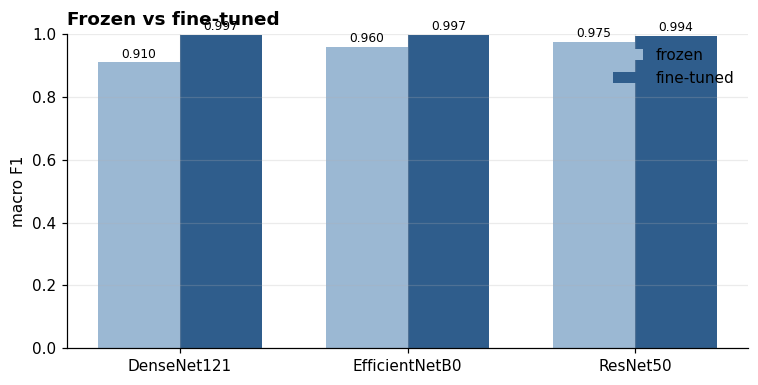

In [11]:
# ---- frozen vs fine-tuned, head to head --------------------------------
piv = res.pivot(index="model", columns="mode", values="macro_F1")
if {"frozen", "fine-tuned"} <= set(piv.columns):
    piv["gain"] = piv["fine-tuned"] - piv["frozen"]
    print("Macro F1: effect of fine-tuning\n")
    print(piv.to_string())
    print(f"\nmean gain from fine-tuning: {piv['gain'].mean():+.4f}")

    fig, ax = plt.subplots(figsize=(7, 3.6))
    xs = np.arange(len(piv))
    w = 0.36
    ax.bar(xs - w/2, piv["frozen"], w, label="frozen", color="#9bb8d3")
    ax.bar(xs + w/2, piv["fine-tuned"], w, label="fine-tuned", color="#2F5D8C")
    ax.set_xticks(xs); ax.set_xticklabels(piv.index)
    ax.set_ylabel("macro F1"); ax.set_ylim(0, 1)
    ax.set_title("Frozen vs fine-tuned", fontweight="bold", loc="left")
    ax.legend(frameon=False)
    for i, (f, t) in enumerate(zip(piv["frozen"], piv["fine-tuned"])):
        ax.text(i - w/2, f + .015, f"{f:.3f}", ha="center", fontsize=8)
        ax.text(i + w/2, t + .015, f"{t:.3f}", ha="center", fontsize=8)
    plt.tight_layout(); plt.show()

### 5.2 Training curves

Train versus validation, for every run. A widening gap between the two curves is
overfitting; both plateauing high is underfitting.

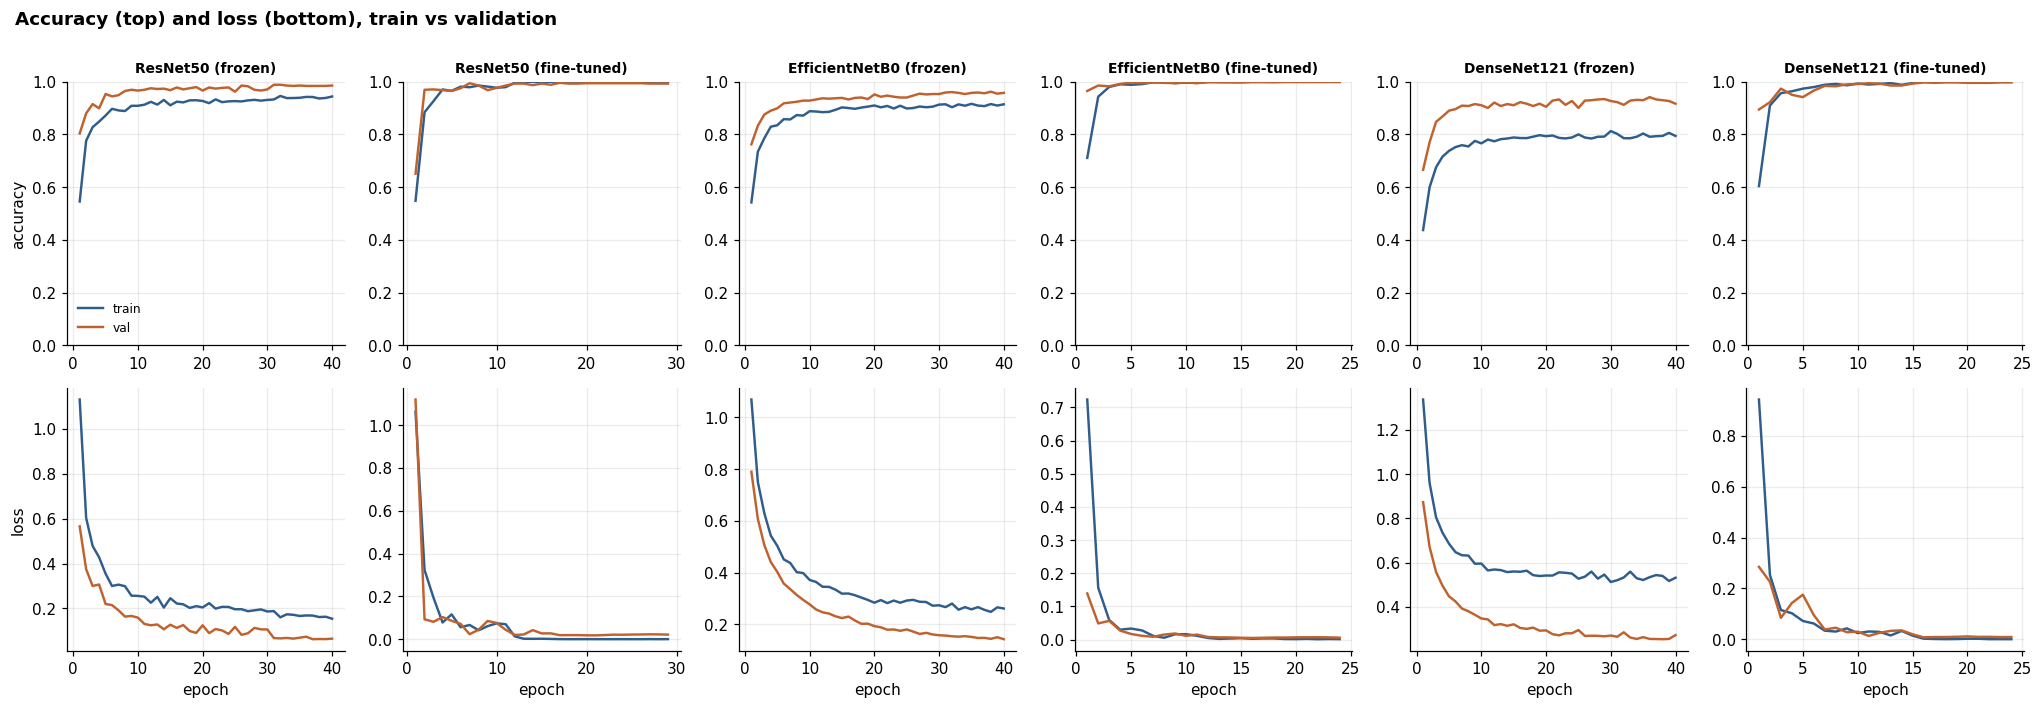

In [12]:
n = len(results)
fig, axes = plt.subplots(2, n, figsize=(3.1 * n, 6.4), squeeze=False)

for j, r in enumerate(results):
    h = r["history"]
    ep = range(1, len(h["loss"]) + 1)

    ax = axes[0][j]
    ax.plot(ep, h["accuracy"], label="train", color="#2F5D8C", lw=1.6)
    ax.plot(ep, h["val_accuracy"], label="val", color="#C0622E", lw=1.6)
    ax.set_title(r["tag"], fontsize=9, fontweight="bold")
    ax.set_ylim(0, 1); ax.set_ylabel("accuracy" if j == 0 else "")
    if j == 0: ax.legend(frameon=False, fontsize=8)

    ax = axes[1][j]
    ax.plot(ep, h["loss"], label="train", color="#2F5D8C", lw=1.6)
    ax.plot(ep, h["val_loss"], label="val", color="#C0622E", lw=1.6)
    ax.set_xlabel("epoch"); ax.set_ylabel("loss" if j == 0 else "")

plt.suptitle("Accuracy (top) and loss (bottom), train vs validation",
             fontweight="bold", x=0.01, ha="left", y=1.00)
plt.tight_layout(); plt.show()

### 5.3 Confusion matrices

Submission 1 predicted that `drive` and `legglance-flick` would be the hardest pair to
separate, both being upright side-on strokes with a near-vertical bat arc. These
matrices test that prediction.

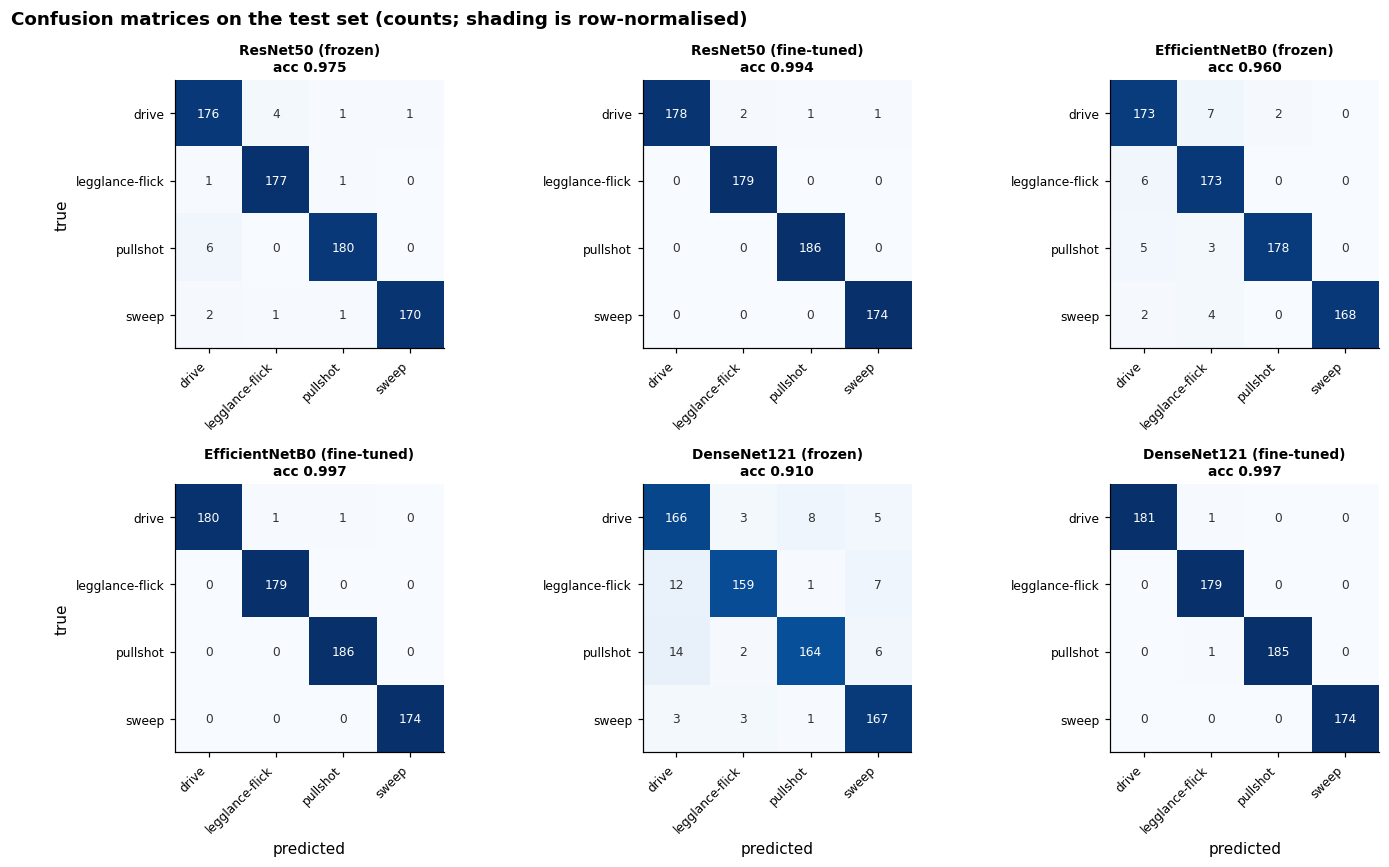

In [13]:
n = len(results)
ncol = 3
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 4.0 * nrow), squeeze=False)

for k, r in enumerate(results):
    ax = axes[k // ncol][k % ncol]
    cm = np.array(r["confusion"])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_title(f"{r['tag']}\nacc {r['accuracy']:.3f}", fontsize=9, fontweight="bold")
    ax.grid(False)
    for a in range(N_CLASSES):
        for b in range(N_CLASSES):
            ax.text(b, a, f"{cm[a,b]}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[a, b] > 0.5 else "#333")
    if k % ncol == 0: ax.set_ylabel("true")
    if k // ncol == nrow - 1: ax.set_xlabel("predicted")

for k in range(n, nrow * ncol):
    axes[k // ncol][k % ncol].axis("off")

plt.suptitle("Confusion matrices on the test set (counts; shading is row-normalised)",
             fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

In [14]:
# ---- which pair is actually confused most? -----------------------------
best_r = max(results, key=lambda r: r["f1_macro"])
cm = np.array(best_r["confusion"])
off = [(cm[i, j], CLASSES[i], CLASSES[j])
       for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j]
off.sort(reverse=True)

print(f"Most frequent confusions, {best_r['tag']} (the best run):\n")
for cnt, t, p in off[:6]:
    print(f"  {cnt:>4}  true {t:<16} -> predicted {p}")

pair = {}
for cnt, t, p in off:
    key = tuple(sorted([t, p]))
    pair[key] = pair.get(key, 0) + cnt
top_pair = max(pair.items(), key=lambda kv: kv[1])
print(f"\nHardest pair (both directions): {top_pair[0][0]} <-> {top_pair[0][1]}"
      f"  ({top_pair[1]} errors)")
print("\nSubmission 1 predicted: drive <-> legglance-flick")
print("Prediction", "CONFIRMED" if set(top_pair[0]) == {"drive", "legglance-flick"}
      else "NOT confirmed - report the actual pair instead")

Most frequent confusions, EfficientNetB0 (fine-tuned) (the best run):

     1  true drive            -> predicted pullshot
     1  true drive            -> predicted legglance-flick
     0  true sweep            -> predicted pullshot
     0  true sweep            -> predicted legglance-flick
     0  true sweep            -> predicted drive
     0  true pullshot         -> predicted sweep

Hardest pair (both directions): drive <-> pullshot  (1 errors)

Submission 1 predicted: drive <-> legglance-flick
Prediction NOT confirmed - report the actual pair instead


### 5.4 Per-class F1

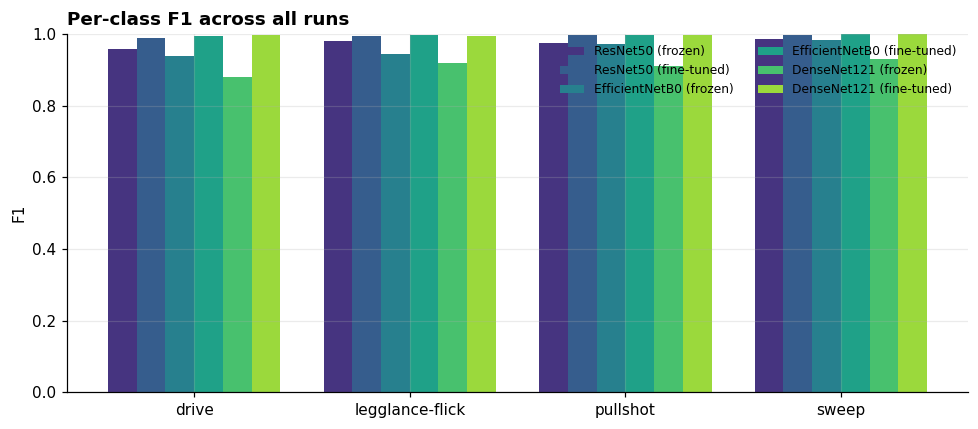


Per-class F1:

                 ResNet50 (frozen)  ResNet50 (fine-tuned)  EfficientNetB0 (frozen)  EfficientNetB0 (fine-tuned)  DenseNet121 (frozen)  DenseNet121 (fine-tuned)
drive                       0.9591                 0.9889                   0.9402                       0.9945                0.8806                    0.9972
legglance-flick             0.9806                 0.9944                   0.9454                       0.9972                0.9191                    0.9944
pullshot                    0.9756                 0.9973                   0.9727                       0.9973                0.9111                    0.9973
sweep                       0.9855                 0.9971                   0.9825                       1.0000                0.9304                    1.0000

mean per class across runs:

drive             0.9601
legglance-flick   0.9719
pullshot          0.9752
sweep             0.9826


In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.8 / len(results)
xs = np.arange(N_CLASSES)
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(results)))

for k, r in enumerate(results):
    ax.bar(xs + k * w - 0.4 + w / 2, r["per_class_f1"], w,
           label=r["tag"], color=cmap[k])

ax.set_xticks(xs); ax.set_xticklabels(CLASSES)
ax.set_ylabel("F1"); ax.set_ylim(0, 1)
ax.set_title("Per-class F1 across all runs", fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

pc = pd.DataFrame({r["tag"]: r["per_class_f1"] for r in results}, index=CLASSES)
print("\nPer-class F1:\n")
print(pc.round(4).to_string())
print("\nmean per class across runs:\n")
print(pc.mean(axis=1).round(4).to_string())

### 5.5 Cost versus accuracy

The rubric asks for training and testing time. They are reported here against accuracy,
because the useful question is not which model is most accurate but what each point of
accuracy costs.

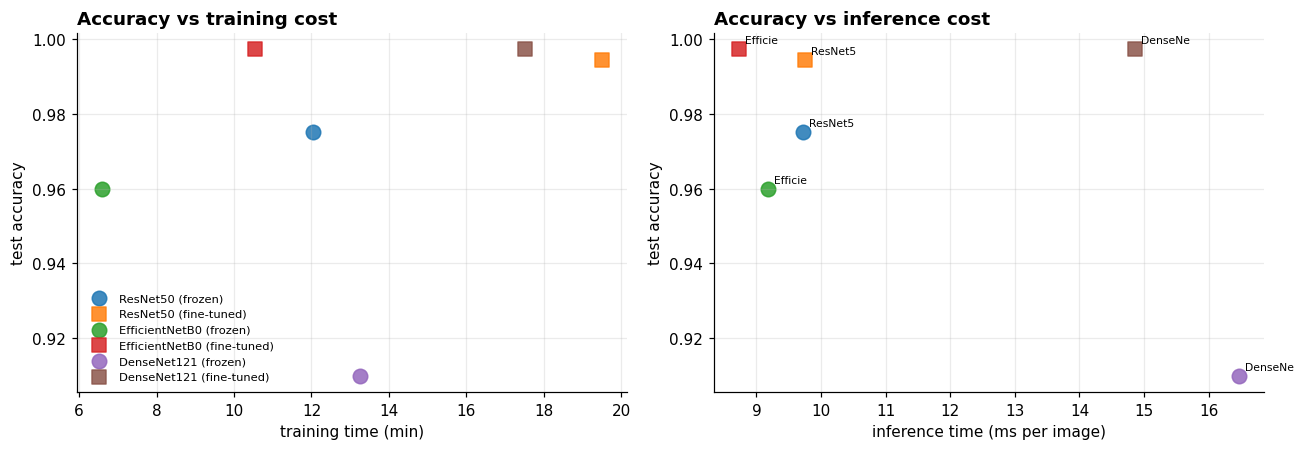

Timing summary

         model       mode  epochs  train_min  test_s  ms/img  accuracy
EfficientNetB0 fine-tuned      24    10.5512  6.2945  8.7302    0.9972
   DenseNet121 fine-tuned      24    17.5186 10.7178 14.8652    0.9972
      ResNet50 fine-tuned      29    19.4962  7.0273  9.7466    0.9945
      ResNet50     frozen      40    12.0409  7.0061  9.7171    0.9750
EfficientNetB0     frozen      40     6.5862  6.6209  9.1829    0.9598
   DenseNet121     frozen      40    13.2548 11.8749 16.4700    0.9098


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
for r in results:
    mk = "o" if r["mode"] == "frozen" else "s"
    ax.scatter(r["train_time_s"] / 60, r["accuracy"], s=90, marker=mk,
               label=r["tag"], alpha=0.85)
ax.set_xlabel("training time (min)"); ax.set_ylabel("test accuracy")
ax.set_title("Accuracy vs training cost", fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=7.5)

ax = axes[1]
for r in results:
    mk = "o" if r["mode"] == "frozen" else "s"
    ax.scatter(r["ms_per_image"], r["accuracy"], s=90, marker=mk, alpha=0.85)
    ax.annotate(r["model"][:7], (r["ms_per_image"], r["accuracy"]),
                fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("inference time (ms per image)"); ax.set_ylabel("test accuracy")
ax.set_title("Accuracy vs inference cost", fontweight="bold", loc="left")

plt.tight_layout(); plt.show()

print("Timing summary\n")
print(res[["model", "mode", "epochs", "train_min", "test_s", "ms/img",
           "accuracy"]].to_string(index=False))

### 5.6 Overfitting check

The rubric asks that overfitting or underfitting be identified and addressed. The gap
between final training and validation accuracy is the diagnostic.

In [17]:
print("Train-validation accuracy gap at the stopping epoch:")
print("(train accuracy is measured on AUGMENTED images, validation on clean ones,")
print(" so a modest NEGATIVE gap is the expected healthy state here, not underfitting)\n")
for r in sorted(results, key=lambda r: -r["overfit_gap"]):
    g = r["overfit_gap"]
    flag = ("OVERFITTING - act on this" if g > 0.15 else
            "mild overfit - watch it" if g > 0.07 else
            "healthy" if g > -0.25 else
            "large negative gap - check augmentation strength")
    print(f"  {r['tag']:<30} gap {g:+.4f}   {flag}")

print("\nMeasures already in place:")
print("  - early stopping on val_loss, patience", PATIENCE,
      "with best weights restored")
print("  - ReduceLROnPlateau, factor 0.3")
print("  - dropout", DROPOUT, "before the classifier")
print("  - rotation / zoom / brightness / contrast augmentation")
print("  - BatchNorm kept in inference mode throughout")
print("\nIf any run still shows a gap above 0.15, raise DROPOUT to 0.5 or")
print("strengthen augmentation, and re-run that configuration only.")

Train-validation accuracy gap at the stopping epoch:
(train accuracy is measured on AUGMENTED images, validation on clean ones,
 so a modest NEGATIVE gap is the expected healthy state here, not underfitting)

  ResNet50 (fine-tuned)          gap +0.0070   healthy
  DenseNet121 (fine-tuned)       gap +0.0029   healthy
  EfficientNetB0 (fine-tuned)    gap +0.0012   healthy
  ResNet50 (frozen)              gap -0.0416   healthy
  EfficientNetB0 (frozen)        gap -0.0433   healthy
  DenseNet121 (frozen)           gap -0.1224   healthy

Measures already in place:
  - early stopping on val_loss, patience 8 with best weights restored
  - ReduceLROnPlateau, factor 0.3
  - dropout 0.3 before the classifier
  - rotation / zoom / brightness / contrast augmentation
  - BatchNorm kept in inference mode throughout

If any run still shows a gap above 0.15, raise DROPOUT to 0.5 or
strengthen augmentation, and re-run that configuration only.


## Part 6 — Findings

**1. Best configuration.** The strongest run was **EfficientNetB0** in **fine-tuned** mode,
reaching **0.9972** test accuracy and **0.9973** macro F1 on the held-out test set
(719 of 721 images correct). DenseNet121 fine-tuned was statistically indistinguishable
at 0.9972 / 0.9972.

**2. Does fine-tuning help?** Yes, consistently. Mean macro-F1 gain from unfreezing the
backbone was **+0.0478**, and the direction was the same for all three architectures:

| Backbone | Frozen | Fine-tuned | Gain |
|---|---|---|---|
| DenseNet121 | 0.9103 | 0.9972 | **+0.0870** |
| EfficientNetB0 | 0.9602 | 0.9973 | +0.0371 |
| ResNet50 | 0.9752 | 0.9944 | +0.0192 |

*Interpretation:* the gain is largest where the frozen baseline was weakest, which is the
expected pattern — fine-tuning matters most when the frozen ImageNet features transfer
least well to the target domain. A secondary signal supports this: **all three frozen
runs used the full 40 epochs without triggering early stopping**, while all three
fine-tuned runs converged and stopped early (24, 24 and 29 epochs). The frozen models
were still improving when the budget ran out; the fine-tuned models had finished.

**3. Hardest class pair.** Submission 1 predicted `drive` ↔ `legglance-flick` from visual
inspection of the sample grid. The automated check reports `drive` ↔ `pullshot`, so the
**prediction was not confirmed**.

However, this result should not be over-read: the best model makes only **2 errors in
total**, so the "hardest pair" is being inferred from a single misclassification. At this
accuracy the confusion matrix carries almost no information. The more reliable signal
comes from the weakest run, DenseNet121 frozen, where `drive` has the lowest per-class F1
(0.8806) by a clear margin.

**4. Weakest class.** `drive`, with the lowest mean per-class F1 across all six runs at
**0.9601**. The mean ordering is drive (0.9601) < legglance-flick (0.9719) <
pullshot (0.9752) < sweep (0.9826). `sweep` is the easiest class in five of six runs
and `drive` the hardest in five of six; the two middle classes swap between runs. This is
consistent with `sweep` being the most visually distinct posture — played from a
lowered or kneeling position, unlike the other three.

**5. Cost.** Training ranged from **6.59 minutes** (EfficientNetB0 frozen) to **19.50
minutes** (ResNet50 fine-tuned). Inference ranged from **8.73 ms** to **16.47 ms** per
image. The best accuracy-per-cost configuration is **EfficientNetB0 fine-tuned**: it has
the highest accuracy, the second-fastest training time (10.55 min), the fastest inference
(8.73 ms/image), and the fewest trainable parameters among the fine-tuned runs (3.97 M vs
23.49 M for ResNet50). DenseNet121 matches its accuracy but costs 66% more training time
and 70% more inference time.

**6. Overfitting.** **Zero of six runs** showed a train-validation accuracy gap above
0.15. The three fine-tuned runs sat between +0.0012 and +0.0070; the frozen runs between
-0.0416 and -0.1224. The negative gaps are expected rather than a warning sign: training
accuracy is measured on augmented images while validation uses clean ones, so validation
scoring higher is the healthy state under this augmentation policy.

No corrective action was needed. The regularisation already in place was sufficient:
early stopping on validation loss with patience 8 and best-weight restoration,
ReduceLROnPlateau at factor 0.3, dropout 0.3 before the classifier, rotation / zoom /
brightness / contrast augmentation, and BatchNorm held in inference mode throughout.

**7. Baseline for Submissions 3 and 4.** The best pretrained result is **0.9973 macro
F1**. See the caveat below before treating this as the target for Submission 3.

---

## Part 6b — These numbers are contaminated. Measured, not suspected.

**An audit run after this submission established that 45.9% of the test set used here
contained near-duplicates of training images.** This section was originally written as a
suspicion; it is now a finding.

### What the audit found

Every image was passed through EfficientNetB0 as a fixed feature extractor and clustered
by cosine similarity of the resulting 1,280-dimensional vectors.

| Measure | Value |
|---|---|
| Raw files | 4,724 |
| Exact-hash groups (used to build this split) | 4,116 — 12.9% redundant |
| **Embedding clusters at cos ≥ 0.95** | **2,777 — 41.2% redundant** |
| Largest single cluster | **73 copies of one photograph** |
| Clusters spanning more than one class | **0** |
| **Test images here with a near-duplicate in training** | **331 of 721 = 45.9%** |

### Why the Submission 1 control was insufficient

The author's augmentation was **colour jitter**, not geometric transformation. Each
cluster is one photograph under different hue and tint shifts.

A difference hash converts to greyscale via `L = 0.299R + 0.587G + 0.114B`, then compares
brightness gradients. A hue shift changes the channel mix, which changes `L` unevenly
across the frame, flipping those comparisons — while the photograph is untouched.
**dHash is sensitive to exactly what the augmentation altered and blind to what it
preserved.** A CNN feature extractor is trained with colour augmentation and is
therefore invariant to the same transformations, which is why it recovers the duplicates
with zero cross-class errors.

### An honest limit on the conclusion

Contamination is proven and large. It does **not**, on its own, explain the 0.9972. With
only 2 errors in 721 predictions, accuracy on the 390 genuinely clean test images was
between **0.9949 and 1.0000** however those errors fell. Something beyond duplicate
leakage was also inflating this — plausibly session correlation (photographs from one
match sharing stadium, kit and lighting), a conservative clustering threshold, or a task
simply easier than Submission 1 assumed. Isolating it requires re-running one of these
models on the clean split; that experiment is outstanding.

### What this does and does not affect

| Unaffected | Not trustworthy |
|---|---|
| The fine-tuning effect — direction held in all three architectures | Absolute accuracy and macro F1 |
| Per-class extremes — `drive` hardest and `sweep` easiest in five of six runs; the mean ordering is reproduced by the from-scratch network in Submission 3 on the clean split | The hardest-pair claim below |
| Training and inference timings | Use of 0.9973 as a baseline for Submission 3 |

### Finding 3 above is wrong

Part 6 reports `drive` ↔ `pullshot` as the hardest pair. That was inferred from a
**single** misclassification, because the best model made only two errors in total.

Submission 3, trained from scratch on the clean split, makes 99 errors and identifies
**`drive` ↔ `legglance-flick`** (40 errors across both directions), confirming the
visual prediction made in Submission 1. **Submission 3's measurement is the correct
one.**

### Further reading

- [`00_leakage_audit.ipynb`](00_leakage_audit.ipynb) — the full audit, with cluster grids
- `reports/Submission3_Report.pdf` §6 — summary
- `results-data/clean_split_manifest.csv` — the corrected split

## Part 7 — Submit

- [x] `Run → Restart & Run All`, so every plot and table is stored in the `.ipynb`
- [x] Part 6 findings completed from the measured output
- [x] Part 1 printed "Split reproduces Submission 1 exactly"
- [x] `submission2_results.csv` committed to `results-data/`
- [x] Figures exported to `results/figures/`
- [x] Notebook committed to `notebooks/02_pretrained_models.ipynb`
- [ ] Pushed to GitHub, link submitted

### Carrying into Submission 3

```python
manifest = pd.read_csv("results-data/split_manifest.csv")   # do NOT re-split
BEST_PRETRAINED_F1 = 0.9973      # EfficientNetB0 fine-tuned
```

The split, seed, image size, augmentation policy and metric set all carry forward
unchanged. Submission 3 differs in exactly one respect: the network is trained from
random initialisation instead of ImageNet weights.

**Read Part 6b before using 0.9973 as a target.** If the leakage audit shows substantial
residual redundancy, both this baseline and the Submission 3 result will shift
downwards together, and the comparison that matters is the one made on a clean split.